# PCA / t-SNE Cognitive Prediction — Baseline Comparison

Directly mirrors `mlp_cognitive_prediction.ipynb`, replacing NOFE graph embeddings
with classical dimensionality-reduction baselines:

| Method | Feature dim | Description |
|---|---|---|
| **NOFE-Whole** | 32 | GNN hidden states, whole-brain mean-pool |
| **NOFE-Region** | 160 | GNN hidden states, 5-region mean-pool |
| **PCA-Whole** | 32 | PCA on raw 143-ch voxels, whole-brain mean-pool |
| **PCA-Region** | 160 | PCA on raw 143-ch voxels, 5-region mean-pool |
| **Raw-Whole** | 143 | Raw DWI channels, whole-brain mean-pool |
| **tSNE-2D** | 2 | Subject-level t-SNE of PCA-Region features |

**Identical sampling**: N_VOXELS=10 000, N_REPEATS=3, same train/test split (12/4, seed=42).

In [1]:
import sys, json, gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from sklearn.decomposition import PCA, IncrementalPCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe

project_root = Path('../../').resolve()
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(project_root / 'dMRI' / 'scripts'))

from utilities import KernelNN
from utilities_dMRI import dMRI_Graph_Generator

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {device}')

def _flush_mps():
    if device.type == 'mps':
        torch.mps.empty_cache()

using Device: mps
Device: mps


## Config — identical to mlp_cognitive_prediction.ipynb

In [ ]:
N_VOXELS     = 10000  # voxels sampled per graph
N_REPEATS    = 3      # graphs averaged per subject
MAX_SUBJECTS = 10     # cap subjects to avoid OOM crash
TEST_SIZE    = 4      # held-out subjects
RANDOM_SEED  = 42
PCA_DIMS     = 32     # matches NOFE hidden width

## 1. Brain Region Masks

Same coordinate-based lobe approximation as the NOFE notebook.

In [3]:
def region_masks(coords):
    """coords: (N, 3) in [0,1].  Returns bool masks per region."""
    y, z = coords[:, 1], coords[:, 2]
    return {
        'frontal':     (y > 0.60),
        'parietal':    (y > 0.35) & (y < 0.85) & (z > 0.62),
        'temporal':    (y > 0.20) & (y < 0.70) & (z < 0.55),
        'occipital':   (y < 0.25),
        'subcortical': (y > 0.35) & (y < 0.65) & (z > 0.28) & (z < 0.58),
    }

REGION_NAMES = ['frontal', 'parietal', 'temporal', 'occipital', 'subcortical']


def build_feature_vectors(feats, coords):
    """Mean-pool over whole brain and per anatomical region."""
    whole = feats.mean(axis=0)
    masks = region_masks(coords)
    parts = []
    for name in REGION_NAMES:
        m = masks[name]
        parts.append(feats[m].mean(axis=0) if m.sum() > 0
                     else np.zeros(feats.shape[1]))
    return whole, np.concatenate(parts)

## 2. Load NOFE Model

In [4]:
model_type   = 'regular'
model_prefix = 'base'

trained_models_path = project_root / 'dMRI' / 'trained_models' / model_type
available = sorted([f.stem for f in trained_models_path.glob(f'{model_prefix}_*.pth')])
if not available:
    raise FileNotFoundError(f'No {model_prefix} model found in {trained_models_path}')
model_id = available[-1]
print(f'Using model: {model_id}')

with open(trained_models_path / 'logs' / 'configs' / f'{model_id}.json') as f:
    config = json.load(f)

nofe_model = KernelNN(
    width     = config['width'],
    ker_width = config['ker_width'],
    depth     = config['depth'],
    in_width  = config['node_features'],
    ker_in    = config['edge_attr'],
    out_width = config['out_width'],
)
nofe_model.load_state_dict(
    torch.load(trained_models_path / f'{model_id}.pth', map_location='cpu')
)
nofe_model.eval().to(device)
print(f'Hidden dim: {config["width"]}  |  PCA_DIMS={PCA_DIMS}')

Using model: base_2026-04-29_t11-16-23
Hidden dim: 32  |  PCA_DIMS=32


## 3. Feature Extraction

In [5]:
@torch.no_grad()
def extract_features(graph):
    """
    Returns:
      hidden: (N, 32)  NOFE pre-output hidden states
      raw:    (N, 143) raw DWI channel features (graph.x)
      coords: (N, 3)   normed voxel coordinates
    """
    x  = graph.x.to(device)
    ei = graph.edge_index.to(device)
    ea = graph.edge_attr.to(device)
    raw    = graph.x.cpu().numpy()             # (N, 143) — copy before MPS ops
    coords = graph.normed_coords.cpu().numpy() # (N, 3)
    x = nofe_model.fc1(x)
    for _ in range(nofe_model.depth):
        x = F.relu(nofe_model.conv1(x, ei, ea))
    hidden = x.cpu().numpy()                   # (N, 32)
    del x, ei, ea                              # release MPS tensors immediately
    _flush_mps()
    return hidden, raw, coords


In [ ]:
data_root    = project_root / 'dMRI' / 'data'
DIFF_SUBPATH = 'T1w/Diffusion_7T/'

local_subjects = sorted([
    d for d in data_root.iterdir()
    if d.is_dir() and d.name.isdigit()
])[:MAX_SUBJECTS]

n_subjects  = len(local_subjects)
subject_ids = [int(d.name) for d in local_subjects]
print(f'Using {n_subjects} subjects: {subject_ids}')

cache_dir  = project_root / 'dMRI' / 'cache'
cache_dir.mkdir(exist_ok=True)
cache_path = cache_dir / f'pca_tsne_features_{model_id}_N{N_VOXELS}_R{N_REPEATS}_S{n_subjects}.npz'

if cache_path.exists():
    print(f'Loading from cache: {cache_path.name}')
    data       = np.load(cache_path, allow_pickle=True)
    all_hidden = [data['hidden'][i]  for i in range(n_subjects)]
    all_raw    = [data['raw'][i]     for i in range(n_subjects)]
    all_coords = [data['coords'][i]  for i in range(n_subjects)]
    assert list(data['subject_ids']) == subject_ids, 'Cache subject order mismatch'
    print(f'Loaded {n_subjects} subjects from cache')
else:
    print(f'Cache not found — extracting features ({n_subjects} subjects) ...')
    Generator = dMRI_Graph_Generator(str(data_root))
    all_hidden, all_raw, all_coords = [], [], []

    for subj_dir in local_subjects:
        path = str(subj_dir / DIFF_SUBPATH) + '/'
        print(f'  {subj_dir.name} ...', end=' ', flush=True)
        Generator.load_data(path=path)

        hidden_list, raw_list, coords_last = [], [], None
        for _ in range(N_REPEATS):
            graph = Generator.sample_graph(
                N               = N_VOXELS,
                k               = config['k'],
                perplexity      = config['perplexity'],
                sampling_method = config['sampling_method'],
                gen_feature_mode= config['feature_mode'],
                sigma_method    = config['sigma_method'],
            )
            h, r, c = extract_features(graph)
            hidden_list.append(h)
            raw_list.append(r)
            coords_last = c
            del graph; _flush_mps()

        all_hidden.append(np.mean(hidden_list, axis=0))
        all_raw.append(np.mean(raw_list, axis=0))
        all_coords.append(coords_last)
        del hidden_list, raw_list
        gc.collect(); _flush_mps()
        print('done')

    np.savez_compressed(
        cache_path,
        hidden      = np.stack(all_hidden),
        raw         = np.stack(all_raw),
        coords      = np.stack(all_coords),
        subject_ids = np.array(subject_ids),
    )
    print(f'Saved cache: {cache_path.name}')

## 4. Cognitive Scores

In [7]:
csv_path = data_root / 'HCP_YA_subjects_2026_04_30_00_43_32.csv'
df = pd.read_csv(csv_path)

TARGETS = {
    'CardSort':  'CardSort_Unadj',
    'Flanker':   'Flanker_Unadj',
    'PMAT24':    'PMAT24_A_CR',
    'ProcSpeed': 'ProcSpeed_Unadj',
    'ListSort':  'ListSort_Unadj',
    'ReadEng':   'ReadEng_Unadj',
    'PicVocab':  'PicVocab_Unadj',
}

local_df = df[df['Subject'].isin(subject_ids)].set_index('Subject')
Y = {}
for name, col in TARGETS.items():
    vals = local_df.loc[subject_ids, col].values.astype(float)
    Y[name] = vals
    print(f'{name:12s}: mean={vals.mean():.1f}  std={vals.std():.1f}')

CardSort    : mean=114.4  std=11.4
Flanker     : mean=109.3  std=7.5
PMAT24      : mean=14.1  std=5.3
ProcSpeed   : mean=115.5  std=17.9
ListSort    : mean=109.3  std=12.2
ReadEng     : mean=118.2  std=12.1
PicVocab    : mean=113.9  std=10.1


## 5. PCA Baseline

PCA is fit **on training subjects' raw voxel features only** (no leakage from test subjects).
n_components=32 matches the NOFE hidden dimension for a fair comparison.

Train subjects: [116726, 118225, 125525, 128935, 130518, 131217, 131722, 132118, 134627, 134829, 135124, 140117]
Test subjects:  [115017, 115825, 126426, 137128]

Variance explained by 32 PCs: 97.9%


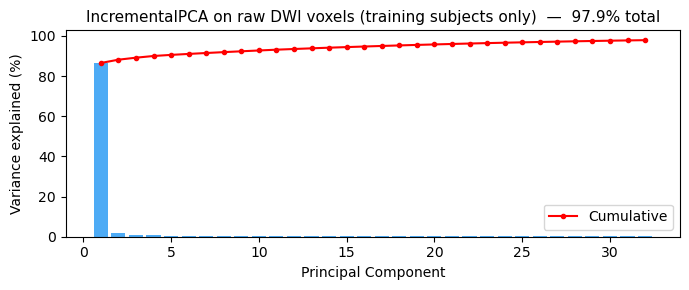

In [8]:
# Identical split to mlp_cognitive_prediction.ipynb
indices = np.arange(n_subjects)
train_idx, test_idx = train_test_split(
    indices, test_size=TEST_SIZE, random_state=RANDOM_SEED
)
print(f'Train subjects: {[subject_ids[i] for i in sorted(train_idx)]}')
print(f'Test subjects:  {[subject_ids[i] for i in sorted(test_idx)]}')

# IncrementalPCA: fit one subject at a time — never allocates the full stacked array
# Standard PCA would need np.vstack (12×10000×143 = 68 MB) on top of all_raw (91 MB)
pca = IncrementalPCA(n_components=PCA_DIMS)
for i in train_idx:
    pca.partial_fit(all_raw[i])   # (N_VOXELS, 143) one subject at a time
gc.collect()

cum_var = pca.explained_variance_ratio_.cumsum()
print(f'\nVariance explained by {PCA_DIMS} PCs: {cum_var[-1]*100:.1f}%')

# Plot explained variance
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(range(1, PCA_DIMS+1), pca.explained_variance_ratio_*100, color='#2196F3', alpha=0.8)
ax.plot(range(1, PCA_DIMS+1), cum_var*100, 'r-o', ms=3, label='Cumulative')
ax.set_xlabel('Principal Component'); ax.set_ylabel('Variance explained (%)')
ax.set_title(f'IncrementalPCA on raw DWI voxels (training subjects only)  —  '
             f'{cum_var[-1]*100:.1f}% total', fontsize=11)
ax.legend()
plt.tight_layout(); plt.show()


## 6. Subject-Level Feature Matrices

In [ ]:
nofe_whole_list  = []
nofe_region_list = []
pca_whole_list   = []
pca_region_list  = []
raw_whole_list   = []

for i in range(n_subjects):
    h = all_hidden[i]          # (N, 32)  NOFE
    r = all_raw[i]             # (N, 143) raw
    c = all_coords[i]          # (N, 3)
    p = pca.transform(r)       # (N, 32)  PCA

    nw, nr = build_feature_vectors(h, c)
    pw, pr = build_feature_vectors(p, c)
    rw, _  = build_feature_vectors(r, c)

    nofe_whole_list.append(nw)
    nofe_region_list.append(nr)
    pca_whole_list.append(pw)
    pca_region_list.append(pr)
    raw_whole_list.append(rw)

X_nofe_whole  = np.stack(nofe_whole_list)   # (n, 32)
X_nofe_region = np.stack(nofe_region_list)  # (n, 160)
X_pca_whole   = np.stack(pca_whole_list)    # (n, 32)
X_pca_region  = np.stack(pca_region_list)   # (n, 160)
X_raw_whole   = np.stack(raw_whole_list)    # (n, 143)

for name, X in [('NOFE-Whole', X_nofe_whole), ('NOFE-Region', X_nofe_region),
                ('PCA-Whole',  X_pca_whole),  ('PCA-Region',  X_pca_region),
                ('Raw-Whole',  X_raw_whole)]:
    print(f'{name:12s}: {X.shape}')

# Free per-voxel arrays — no longer needed after this cell
del all_raw, all_hidden, all_coords
gc.collect()
print('Per-voxel arrays freed from memory')


NOFE-Whole  : (16, 32)
NOFE-Region : (16, 160)
PCA-Whole   : (16, 32)
PCA-Region  : (16, 160)
Raw-Whole   : (16, 143)
Per-voxel arrays freed from memory


/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/sklearn/decomposition/_base.py:155: RuntimeWarning: divide by zero encountered in matmul
  X_transformed -= xp.reshape(self.mean_, (1, -1)) @ self.components_.T
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/sklearn/decomposition/_base.py:155: Runti

: 

## 7. Subject-Level t-SNE

t-SNE is applied to the (n_subjects × 160) PCA-Region feature matrix,
producing 2-D subject coordinates that are also used as prediction features.

In [ ]:
perp = min(5, n_subjects - 1)  # perplexity must be < n_subjects
tsne = TSNE(n_components=2, perplexity=perp, random_state=RANDOM_SEED, max_iter=2000)
X_tsne = tsne.fit_transform(X_pca_region)   # (n_subjects, 2)
print(f't-SNE embedding: {X_tsne.shape}')

# Visualize: one subplot per cognitive score, colour = score value
ncols = 4
nrows = (len(TARGETS) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*4, nrows*4), facecolor='white')
axes = axes.ravel()

for ax, (target, y) in zip(axes, Y.items()):
    sc = ax.scatter(X_tsne[:, 0], X_tsne[:, 1],
                    c=y, cmap='RdYlBu_r', s=140, edgecolors='white', lw=0.8, zorder=3)
    plt.colorbar(sc, ax=ax, shrink=0.8)
    for i, sid in enumerate(subject_ids):
        ax.annotate(str(sid), (X_tsne[i, 0], X_tsne[i, 1]),
                    fontsize=6.5, ha='center', va='bottom',
                    path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])
    # Highlight train/test
    ax.scatter(X_tsne[test_idx, 0], X_tsne[test_idx, 1],
               s=160, facecolors='none', edgecolors='black', lw=1.5, zorder=4,
               label='test')
    ax.set_title(target, fontsize=10, fontweight='bold')
    ax.set_xlabel('t-SNE 1', fontsize=8); ax.set_ylabel('t-SNE 2', fontsize=8)
    ax.set_facecolor('white')
    for spine in ax.spines.values(): spine.set_edgecolor('#dddddd')

for ax in axes[len(TARGETS):]: ax.axis('off')
axes[0].legend(fontsize=8, loc='upper right')
fig.suptitle('Subject t-SNE (from PCA-Region features)  —  colour = cognitive score\n'
             'square outline = test subject',
             fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

## 8. MLP Training

In [ ]:
class CognitiveMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=16, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 8),
            nn.ReLU(),
            nn.Linear(8, 1),
        )
    def forward(self, x): return self.net(x).squeeze(-1)


def run_mlp(X, y, train_idx, test_idx, model_fn, epochs=1000, lr=1e-3):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    sx = StandardScaler().fit(X_train)
    sy = StandardScaler().fit(y_train.reshape(-1, 1))
    Xtr = torch.tensor(sx.transform(X_train), dtype=torch.float32)
    ytr = torch.tensor(sy.transform(y_train.reshape(-1, 1)).ravel(), dtype=torch.float32)
    Xte = torch.tensor(sx.transform(X_test),  dtype=torch.float32)
    net = model_fn()
    opt = Adam(net.parameters(), lr=lr, weight_decay=1e-3)
    for _ in range(epochs):
        net.train(); opt.zero_grad()
        F.mse_loss(net(Xtr), ytr).backward(); opt.step()
    net.eval()
    with torch.no_grad():
        preds = sy.inverse_transform(net(Xte).numpy().reshape(-1, 1)).ravel()
    return y_test, preds


def metrics(y_true, y_pred):
    return {'MAE':  np.mean(np.abs(y_true - y_pred)),
            'RMSE': np.sqrt(np.mean((y_true - y_pred)**2))}

In [ ]:
dim = config['width']  # 32

METHODS = {
    'NOFE-Whole':  (X_nofe_whole,  lambda: CognitiveMLP(dim,       hidden_dim=16)),
    'NOFE-Region': (X_nofe_region, lambda: CognitiveMLP(dim * 5,   hidden_dim=32)),
    'PCA-Whole':   (X_pca_whole,   lambda: CognitiveMLP(dim,       hidden_dim=16)),
    'PCA-Region':  (X_pca_region,  lambda: CognitiveMLP(dim * 5,   hidden_dim=32)),
    'Raw-Whole':   (X_raw_whole,   lambda: CognitiveMLP(143,       hidden_dim=32)),
    'tSNE-2D':     (X_tsne,        lambda: CognitiveMLP(2,         hidden_dim=8)),
}

results = {}
for target, y in Y.items():
    print(f'\n=== {target} ===')
    results[target] = {}
    for method, (X, mfn) in METHODS.items():
        y_test, preds = run_mlp(X, y, train_idx, test_idx, model_fn=mfn)
        results[target][method] = (y_test, preds)
        m = metrics(y_test, preds)
        print(f'  {method:14s}  MAE={m["MAE"]:.2f}  RMSE={m["RMSE"]:.2f}')

## 9. Results

In [ ]:
method_names = list(METHODS.keys())

rows = []
for target in TARGETS:
    for method in method_names:
        y_test, preds = results[target][method]
        m = metrics(y_test, preds)
        rows.append({'Target': target, 'Method': method,
                     'MAE': round(m['MAE'], 2), 'RMSE': round(m['RMSE'], 2)})

result_df = pd.DataFrame(rows)
pivot_mae = result_df.pivot(index='Target', columns='Method', values='MAE')[method_names]

print('MAE summary (lower = better):')
display(pivot_mae)
print('\nMean MAE across all scores:')
display(pivot_mae.mean().rename('mean_MAE').round(2))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5), facecolor='white')

for ax, metric_key in zip(axes, ['MAE', 'RMSE']):
    pivot = result_df.pivot(
        index='Target', columns='Method', values=metric_key
    )[method_names]
    vals = pivot.values.astype(float)

    ax.set_facecolor('white')
    im = ax.imshow(vals, aspect='auto', cmap='RdYlGn_r',
                   vmin=vals.min(), vmax=vals.max())
    ax.set_xticks(range(len(method_names)))
    ax.set_xticklabels(method_names, rotation=35, ha='right', fontsize=10)
    ax.set_yticks(range(len(TARGETS)))
    ax.set_yticklabels(list(TARGETS.keys()), fontsize=10)

    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            v = vals[i, j]
            norm_v = (v - vals.min()) / (vals.max() - vals.min() + 1e-9)
            txt = 'white' if norm_v > 0.65 else '#111111'
            ax.text(j, i, f'{v:.1f}', ha='center', va='center',
                    fontsize=9, color=txt, fontweight='bold')

    # Mark best (min) in each row
    for i in range(vals.shape[0]):
        j_best = int(np.argmin(vals[i]))
        ax.add_patch(plt.Rectangle(
            (j_best - 0.48, i - 0.48), 0.96, 0.96,
            fill=False, edgecolor='gold', lw=2.5, zorder=5
        ))

    plt.colorbar(im, ax=ax, fraction=0.03)
    ax.set_title(f'{metric_key}  (gold border = best per row)',
                 fontsize=12, fontweight='bold')
    for spine in ax.spines.values(): spine.set_edgecolor('#dddddd')

fig.suptitle(f'NOFE vs PCA vs Raw vs t-SNE  '
             f'(train={n_subjects - TEST_SIZE}, test={TEST_SIZE})',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

In [ ]:
METHOD_COLORS = {
    'NOFE-Whole':  '#1565C0',
    'NOFE-Region': '#42A5F5',
    'PCA-Whole':   '#E65100',
    'PCA-Region':  '#FFA726',
    'Raw-Whole':   '#2E7D32',
    'tSNE-2D':     '#7B1FA2',
}

ncols = 4
nrows = (len(TARGETS) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols,
                          figsize=(ncols * 4, nrows * 3.5), facecolor='white')
axes = axes.ravel()

for ax, (target, y) in zip(axes, Y.items()):
    maes = [metrics(results[target][m][0], results[target][m][1])['MAE']
            for m in method_names]
    bars = ax.bar(range(len(method_names)), maes,
                  color=[METHOD_COLORS[m] for m in method_names],
                  alpha=0.88, edgecolor='white', lw=0.8)
    # gold border on best
    best = int(np.argmin(maes))
    bars[best].set_edgecolor('gold'); bars[best].set_linewidth(2.5)
    ax.set_xticks(range(len(method_names)))
    ax.set_xticklabels([m.replace('-', '\n') for m in method_names], fontsize=7)
    ax.set_ylabel('MAE', fontsize=8)
    ax.set_title(target, fontsize=10, fontweight='bold')
    ax.set_facecolor('white')
    for spine in ax.spines.values(): spine.set_edgecolor('#dddddd')

for ax in axes[len(TARGETS):]: ax.axis('off')

legend_patches = [mpatches.Patch(color=c, label=m)
                  for m, c in METHOD_COLORS.items()]
fig.legend(handles=legend_patches, loc='lower right',
           fontsize=9, bbox_to_anchor=(0.98, 0.05), ncol=2,
           framealpha=0.9)
fig.suptitle('MAE per cognitive score  (gold border = best)',
             fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

In [ ]:
best_method_per_target = {
    t: min(method_names,
           key=lambda m: metrics(results[t][m][0], results[t][m][1])['MAE'])
    for t in TARGETS
}

FLUID_TARGETS = {'CardSort', 'Flanker', 'PMAT24', 'ProcSpeed', 'ListSort'}
FLUID_COLOR   = '#1565C0'
CRYST_COLOR   = '#C0392B'

ncols = 4
nrows = (len(TARGETS) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols,
                          figsize=(ncols * 4, nrows * 4), facecolor='#f7f9fc')
axes = axes.ravel()

for ax, (target, _) in zip(axes, Y.items()):
    bm = best_method_per_target[target]
    y_true, y_pred = results[target][bm]
    color = FLUID_COLOR if target in FLUID_TARGETS else CRYST_COLOR

    lo = min(y_true.min(), y_pred.min()) - 3
    hi = max(y_true.max(), y_pred.max()) + 3

    ax.set_facecolor('#f7f9fc')
    ax.plot([lo, hi], [lo, hi], color='#aaaaaa', lw=1.2, ls='--', zorder=1)
    ax.scatter(y_true, y_pred, s=100, color=color,
               edgecolors='white', lw=0.8, zorder=3, alpha=0.9)

    for xt, xp in zip(y_true, y_pred):
        ax.annotate(f'{xt:.0f}\u2192{xp:.0f}', (xt, xp),
                    textcoords='offset points', xytext=(5, 4), fontsize=6.5,
                    color='#333333',
                    path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])

    mae_val = metrics(y_true, y_pred)['MAE']
    group   = 'Fluid' if target in FLUID_TARGETS else 'Crystallized'
    ax.set_title(f'{target}  [{group}]\n{bm}  |  MAE={mae_val:.1f}',
                 fontsize=9, fontweight='bold', color=color)
    ax.set_xlabel('Actual', fontsize=8); ax.set_ylabel('Predicted', fontsize=8)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.tick_params(labelsize=7)
    for spine in ax.spines.values(): spine.set_edgecolor('#cccccc')

for ax in axes[len(TARGETS):]: ax.axis('off')
fig.suptitle('Predicted vs Actual  (best method per score)',
             fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()